In [1]:
import nugget
import matplotlib.pyplot as plt
import numpy as np

In [2]:
GEOM = '../other/800_40_40_geom.csv'
TRAIN_PARQUET = 'big_mu_accepted.parquet'
TEST_PARQUET = './flow_models/mc_reco_muon_flow_v2ns_test_samples.parquet'
CHECKPOINT = './flow_models/best_mc_reco_muon_flow_model_v2ns.pt'

In [3]:
flow = nugget.surrogates.FlowMatchReco.FlowMatchReco(
    device="cuda:3",
    # 'essential': relative position, PMT orientation, q_tot, t_first, t50 (+ token flags);
    # 'thesis': all 27 features of Bas 2026, Table 8.1
    feature_set='thesis',
    # --- PMT transformer encoder (token/pooling layout of Bas 2026, Sec. 8.1-8.2) ---
    d_model=96,
    encoder_depth=20,
    n_heads=4,
    ffn_dim=512,
    cond_dim=256,
    encoder_dropout=0.0,

    # --- adaLN-Zero vector field on R x S^2 ---
    width=256,
    depth=8,
    time_dim=64,
    mlp_ratio=2,
    dropout=0.0,

    # --- token transforms (thesis Eq. 8.2); 'asinh' keeps ns-level timing visible ---
    length_scale=500.0,
    time_scale=1e4,
    time_transform='linear',

    # --- flow ---
    sigma_min=1e-4,
    direction_loss_weight=1.0,
    n_flow_samples=8,       # flow-time draws per encoded event; the encoder dominates cost

    # --- optimisation (thesis Table B.2: warm-up 2000 steps, cosine to 1e-5) ---
    learning_rate=2e-4,
    weight_decay=1e-5,
    lr_schedule='warmup_cosine',
    warmup_steps=2000,
    min_lr=1e-5,
    amp=True,               # bf16 autocast for training; sampling/log_prob stay float32
)

In [4]:
flow.load_model(CHECKPOINT)

FlowMatchReco: thesis features, encoder d_model=96 depth=10 (1,509,830 params), field width=256 depth=12 (4,163,844 params)


In [11]:
data_kw = dict(
    geometry_csv_path=GEOM,
    energy_column='neutrino_energy',
    # photons -> pulses with the thesis/P-ONE Offline PMT response (Table 5.3)
    use_pulses=True,
    pulse_params=None,
    # >= 3 PMTs of one OM within 10 ns, evaluated after masking
    require_trigger=True,
    # every event is seen in its own random sub-geometry of the 1378-string grid: 10-150
    # strings drawn around a random string with a Gaussian width log-uniform in 40-1000 m
    # (compact 40 m cluster ... scattered), then in half the events up to 50% of the OMs
    # dropped. ~14% of (event, geometry) draws trigger; the rest are redrawn.
    n_strings_range=(2000, 2000),
    # string_spread_range=(2000.0, 2000.0),
    om_drop_prob=0.0,
    # om_drop_range=(0.0, 0.5),
    # one token per active silent OM on a hit string and per active silent string, so the
    # whole sub-geometry is seen: ~250 tokens/event median, ~1.4k p99. max_tokens is only a
    # guard against rare huge events; lower batch_size first if memory runs out.
    silent_tokens=False,
    max_tokens=10000,
    batch_size=1000,
    num_workers=8,
)

In [13]:
loader = flow.create_reco_parquet_val_dataloader(
        parquet_path=TEST_PARQUET, num_events_per_epoch=20000, **data_kw)

RecoFlowDataset: 48,669 events, 4,930,778 hit-PMT rows, 34,357,996 photons, 20,000 events/epoch
  hit PMTs/event: median 41, p99 1150, max 6078; log10 E in [2.00, 6.00]
  pulses=on, trigger=on, features=thesis, silent tokens=off, max_tokens=10000
  geometry: 1378 strings; per event (2000, 2000) random strings, OM dropout (0.0, 0.5) with prob 0.0


In [14]:
true_energies = []
true_directions = []
reconstructed_energies = []
reconstructed_directions = []
for i, (feats, mask, glob, le, d) in enumerate(loader):
    # if i >= 100:
    #     break
    rec = flow.reconstruct(feats, mask, glob, 128, 32)
    true_energies.extend(10**le.cpu().numpy())
    true_directions.extend(d.cpu().numpy())
    reconstructed_energies.extend(10 ** rec['log10_energy'].cpu().numpy())
    reconstructed_directions.extend(rec['direction'].detach().cpu().numpy())

[W1102 14:38:08.958622799 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 3 while trying to allocate 4674551808 bytes (free: 3825860608, total: 42430300160).
[W1102 14:39:46.086006969 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 3 while trying to allocate 6211764224 bytes (free: 2685009920, total: 42430300160).


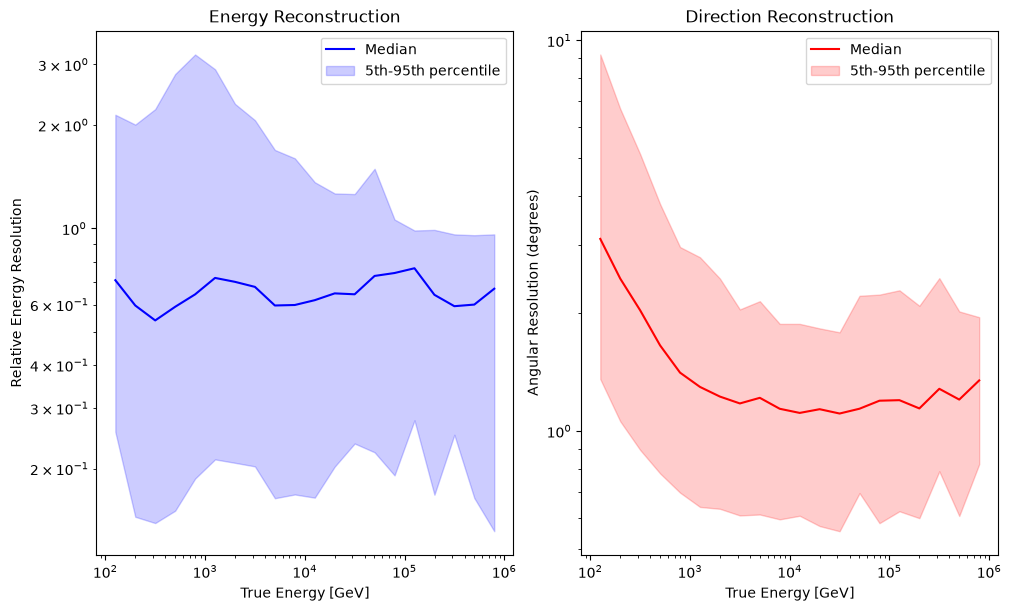

In [15]:
# Plot the median and 5th-95th percentile bands versus true energy.
true_energies = np.asarray(true_energies).ravel()
bin_edges = np.logspace(2, 6, 21)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])

def binned_quantiles(values, energies=true_energies):
    values = np.asarray(values)
    energies = np.asarray(energies)
    if values.shape[0] != energies.shape[0]:
        raise ValueError(f'Expected one value per energy, got {values.shape[0]} values and {energies.shape[0]} energies')
    values = values.reshape(values.shape[0], -1)
    if values.shape[1] != 1:
        raise ValueError('Binned values must contain exactly one value per event')
    values = values[:, 0]
    medians, q05s, q95s = [], [], []
    for lower, upper in zip(bin_edges[:-1], bin_edges[1:]):
        bin_values = values[(energies >= lower) & (energies < upper)]
        bin_values = bin_values[np.isfinite(bin_values)]
        if bin_values.size:
            medians.append(np.median(bin_values))
            q05s.append(np.percentile(bin_values, 16))
            q95s.append(np.percentile(bin_values, 84))
        else:
            medians.append(np.nan)
            q05s.append(np.nan)
            q95s.append(np.nan)
    return np.asarray(medians), np.asarray(q05s), np.asarray(q95s)

relative_energy_resolution = np.abs(
    np.asarray(reconstructed_energies).ravel() - true_energies
) / true_energies
energy_median, energy_q05, energy_q95 = binned_quantiles(relative_energy_resolution)

true_directions_array = np.asarray(true_directions)
reconstructed_directions_array = np.asarray(reconstructed_directions)
dot_products = np.sum(true_directions_array * reconstructed_directions_array, axis=1)
norm_true = np.linalg.norm(true_directions_array, axis=1)
norm_rec = np.linalg.norm(reconstructed_directions_array, axis=1)
cos_theta = dot_products / (norm_true * norm_rec)
angular_resolution = np.degrees(np.arccos(np.clip(cos_theta, -1.0, 1.0)))
angular_median, angular_q05, angular_q95 = binned_quantiles(angular_resolution)

fig, axes = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)
axes[0].plot(bin_centers, energy_median, color='b', label='Median')
axes[0].fill_between(
    bin_centers, energy_q05, energy_q95, color='b', alpha=0.2,
    label='5th-95th percentile'
)
axes[0].set_xlabel('True Energy [GeV]')
axes[0].set_ylabel('Relative Energy Resolution')
axes[0].set_title('Energy Reconstruction')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].legend()

axes[1].plot(bin_centers, angular_median, color='r', label='Median')
axes[1].fill_between(
    bin_centers, angular_q05, angular_q95, color='r', alpha=0.2,
    label='5th-95th percentile'
)
axes[1].set_xlabel('True Energy [GeV]')
axes[1].set_ylabel('Angular Resolution (degrees)')
axes[1].set_title('Direction Reconstruction')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].legend()
